In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy import interpolate
from scipy.stats import gaussian_kde
import glob
import pickle
import matplotlib

from os.path import normpath, basename

matplotlib.rcParams['font.size'] = 8.0
matplotlib.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'

In [7]:
Fs          = 3e4    #data sampling rate from orig
FS_ORIG     = 100    # natural behaviour video sampling rate
TimeHistory = 0.02   # 20ms pre-spike window (have not added post at all)
L           = int(TimeHistory * Fs)  # 600 samples, only consider length before 0

OUTPUT_PATH = "./dataFolder/4_NaturalBehavior/"
BEH_PATH      = "./dataFolder/4_NaturalBehavior/ProboscisMovement-BehaviorData/"

In [22]:
moth_files = glob.glob(BEH_PATH + "MV_*.csv")
moth_files.sort()
moth_data = {}

for f in moth_files:
    moth_name = basename(normpath(f)).replace(".csv", "")
    df    = pd.read_csv(f, index_col=0)
    angle = df.iloc[:, 0].values.astype(float)
    angle = pd.Series(angle).interpolate().values  # fill any NaNs before upsampling - M4 and m9 had quite a few
    angle_degrees = np.degrees(angle)              # convert radians to degrees
    t_orig = np.arange(len(angle)) / FS_ORIG       # original time axis at 100Hz
    t_new  = np.arange(0, t_orig[-1], 1 / Fs)      # new time axis at 30kHz
    cs = interpolate.CubicSpline(t_orig, angle_degrees)  # fit cubic spline upsample for points from 100hz 
    moth_data[moth_name] = cs(t_new)               # evaluate at 30khz
    print(f"{moth_name}: {len(angle)} → {len(moth_data[moth_name])} samples ({len(moth_data[moth_name])/Fs:.1f}s)")
    
# Save the dictionary to a file
with open('./dataFolder/4_NaturalBehavior/allmothMovement.pickle', 'wb') as file:
    pickle.dump(moth_data, file)

MV_m11_130802_errorAngle: 1000 → 299700 samples (10.0s)
MV_m13_130802_errorAngle: 1000 → 299700 samples (10.0s)
MV_m14_130806_errorAngle: 1000 → 299700 samples (10.0s)
MV_m1_130802_errorAngle: 1000 → 299700 samples (10.0s)
MV_m4_130802_errorAngle: 1000 → 299700 samples (10.0s)
MV_m5_130802_errorAngle: 1000 → 299700 samples (10.0s)
MV_m8_130805_errorAngle: 1000 → 299700 samples (10.0s)
MV_m9_130801_errorAngle: 1000 → 299700 samples (10.0s)


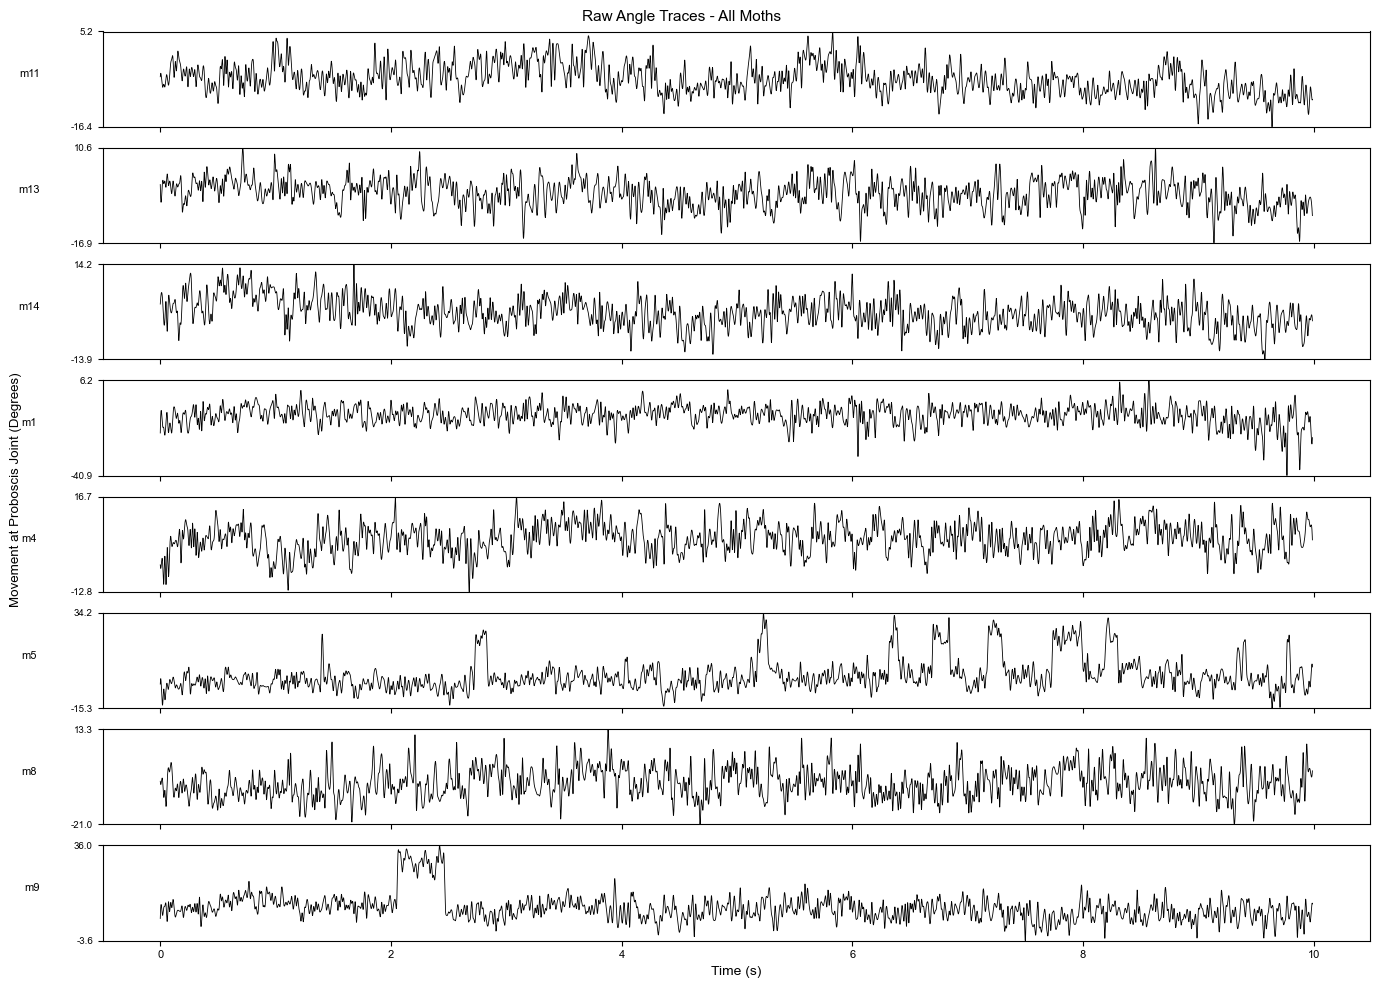

In [23]:
fig, axes = plt.subplots(len(moth_data), 1, figsize=(14, 10), sharex=True)

for ax, (moth_name, upsampled) in zip(axes, moth_data.items()):
    time = np.arange(len(upsampled)) / Fs          # time axis in seconds
    ax.plot(time, upsampled, lw=0.6, color='black')
    ax.set_ylabel(moth_name.split("_")[1], fontsize=8, rotation=0, labelpad=30)
    ymin = np.round(np.min(upsampled), 1)
    ymax = np.round(np.max(upsampled), 1)
    ax.set_ylim(ymin, ymax)
    ax.set_yticks([ymin, ymax])
    ax.set_yticklabels([ymin, ymax], fontsize=7)

fig.supylabel('Movement at Proboscis Joint (Degrees)')
axes[-1].set_xlabel("Time (s)", fontsize=10)
fig.suptitle("Raw Angle Traces - All Moths", fontsize=11)
plt.tight_layout()

plt.savefig('./dataFolder/Figures/NaturalBehavior/allMoths_angle')
plt.show()

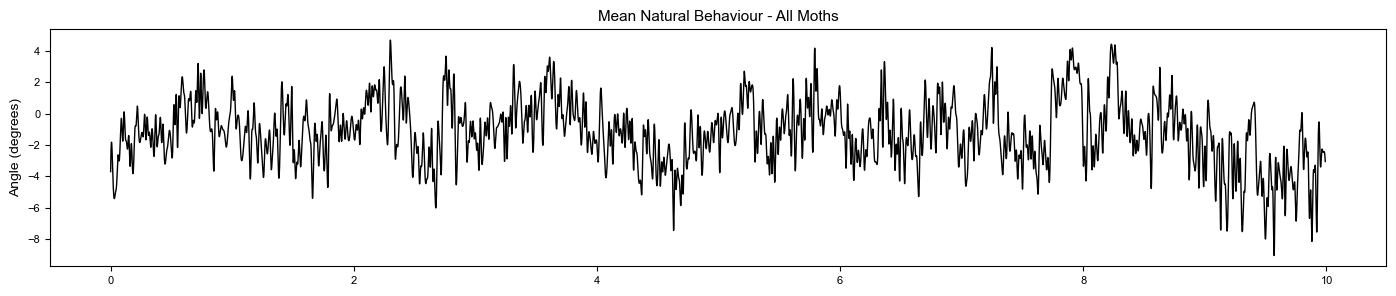

In [11]:
all_traces = np.array(list(moth_data.values()))
mean_trace = np.mean(all_traces, axis=0)           # average across all moths which will be used for the figure.
time_full  = np.arange(len(mean_trace)) / Fs

plt.figure(figsize=(14, 3))
plt.plot(time_full, mean_trace, lw=1.0, color='black')
plt.ylabel("Angle (degrees)", fontsize=10)
plt.title("Mean Natural Behaviour - All Moths", fontsize=11)
plt.tight_layout()
filename = ('./dataFolder/Figures/NaturalBehavior/' + 'MeanWaveformAllMoths.pdf')
plt.savefig(filename)
plt.show()